# Natural Language Processing (CS4063)
# Assignment 1: Advanced Text Similarity and Word Representations

**Name:** Abdullah Bin Ahmed  
**Roll Number:** L227444  
**Course:** Natural Language Processing (CS4063)  
**Date:** 12 September 2026

---

**CLO2:** Represent documents and words as vectors for a variety of NLP tasks

## Personalized Reading Assistant

This notebook builds a content-recommendation engine that takes a user's text (a favorite review) and finds the most relevant movie reviews in the dataset.

We compare two families of vector representations:

| Method | Vector type | What it captures |
|---|---|---|
| **TF-IDF** | Sparse | Distinctive keywords and lexical overlap |
| **Word2Vec (CBOW)** | Dense | Semantic meaning from surrounding context |
| **Word2Vec (Skip-gram)** | Dense | Semantic meaning, stronger on rarer words |

**Dataset:** NLTK `movie_reviews` corpus (2,000 labeled IMDB-style reviews, 1,000 positive and 1,000 negative). This is a standard academic movie-review collection and matches the assignment's suggested domain.

**Tasks**
1. Data preprocessing and exploration
2. TF-IDF cosine-similarity recommendations
3. Word2Vec (CBOW and Skip-gram) recommendations
4. Comparative analysis

## 0. Setup: imports and environment

In [1]:
import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import movie_reviews, stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from gensim.models import Word2Vec
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Save plots so they can also be used in the written report
os.makedirs("figures", exist_ok=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Download NLTK resources if they are not already present.
# Tokenization in this notebook uses a regex tokenizer, so punkt is optional.
for resource in ["movie_reviews", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

print("NLTK resources ready.")

NLTK resources ready.


## Dataset loading

Each document is a full movie review with a sentiment label (`pos` or `neg`). Labels are **not** used to train the similarity engine; they are kept only for later qualitative analysis (do recommendations stay in the same sentiment as the query?).

In [3]:
records = []
for fileid in movie_reviews.fileids():
    records.append({
        "doc_id": fileid,
        "sentiment": movie_reviews.categories(fileid)[0],
        "text": movie_reviews.raw(fileid),
    })

df = pd.DataFrame(records)
df["n_chars"] = df["text"].str.len()
df["n_words_raw"] = df["text"].str.split().str.len()

print(f"Documents: {len(df)}")
print(df["sentiment"].value_counts().to_string())
print("\nReview-length summary:")
display(df[["n_chars", "n_words_raw"]].describe().round(1))
df.head(3)

Documents: 2000
sentiment
neg    1000
pos    1000

Review-length summary:


,n_chars,n_words_raw
count,2000.0,2000.0
mean,3893.0,746.3
std,1712.4,328.4
min,91.0,17.0
25%,2737.8,526.8
50%,3622.5,696.5
75%,4720.2,904.0
max,14957.0,2678.0


,doc_id,sentiment,text,n_chars,n_words_raw
0,neg/cv000_29416.txt,neg,"plot : two teen couples go to a church party ,...",4043,825
1,neg/cv001_19502.txt,neg,the happy bastard's quick movie review \ndamn ...,1370,278
2,neg/cv002_17424.txt,neg,it is movies like these that make a jaded movi...,2848,547


---
# Task 1: Data Preprocessing and Exploration

## 1a. Preprocessing pipeline

Raw reviews contain punctuation, mixed case, URLs, and many function words that do not help similarity. The pipeline below prepares text for both TF-IDF and Word2Vec:

1. **Remove URLs** — web links are not topical content.
2. **Lowercasing** — `Great` and `great` should be the same token.
3. **Remove special characters** — keep alphabetic tokens only.
4. **Tokenization** — split the cleaned string into words.
5. **Stopword removal** — drop high-frequency function words (`the`, `and`, `is`, ...).
6. **Lemmatization** — map inflected forms to a dictionary base (`movies` → `movie`, `better` stays `better` as an adjective default; verbs like `watching` → `watching` unless POS-tagged). We use WordNet lemmatization, which is gentler than stemming and better for embeddings.

In [4]:
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
NON_ALPHA_RE = re.compile(r"[^a-z\s]")

STOP_WORDS = set(stopwords.words("english"))
# Domain words that appear in almost every review and add little topical signal
STOP_WORDS.update({"movie", "movies", "film", "films", "one", "also", "would", "could"})

lemmatizer = WordNetLemmatizer()


def preprocess(text):
    """Clean a raw review and return a list of lemma tokens."""
    text = URL_RE.sub(" ", str(text))
    text = text.lower()
    text = NON_ALPHA_RE.sub(" ", text)          # special characters / digits
    tokens = text.split()                       # tokenization
    cleaned = []
    for tok in tokens:
        if len(tok) <= 2 or tok in STOP_WORDS:
            continue
        lemma = lemmatizer.lemmatize(tok)
        if lemma not in STOP_WORDS and len(lemma) > 2:
            cleaned.append(lemma)
    return cleaned


# Apply to the full corpus
df["tokens"] = df["text"].apply(preprocess)
df["clean_text"] = df["tokens"].apply(lambda toks: " ".join(toks))
df["n_tokens"] = df["tokens"].str.len()

print(f"Average tokens per review after cleaning: {df['n_tokens'].mean():.1f}")
print(f"Empty documents (should be 0): {(df['n_tokens'] == 0).sum()}")
print("\n--- Before vs after (first review, truncated) ---")
print("RAW:", df.loc[0, "text"][:350].replace("\n", " "))
print("\nCLEAN:", df.loc[0, "clean_text"][:350])

Average tokens per review after cleaning: 331.6
Empty documents (should be 0): 0

--- Before vs after (first review, truncated) ---
RAW: plot : two teen couples go to a church party , drink and then drive .  they get into an accident .  one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares .  what's the deal ?  watch the movie and " sorta " find out . . .  critique : a mind-fuck movie for the teen generation that touches on a very cool idea 

CLEAN: plot two teen couple church party drink drive get accident guy girlfriend continues see life nightmare deal watch sorta find critique mind fuck teen generation touch cool idea present bad package make review even harder write since generally applaud attempt break mold mess head lost highway memento good bad way making type folk snag correctly seem 


## 1b. Exploration and visualization

We inspect the most frequent **unigrams**, **bigrams**, and **trigrams**, then plot word distributions with bar charts and a word cloud. These plots show what topical language dominates the corpus (actors, genres, evaluation words).

In [5]:
def top_ngrams(corpus_strings, ngram_range, k=15):
    """Return the k most frequent n-grams from already-preprocessed text."""
    vec = CountVectorizer(ngram_range=ngram_range, min_df=2)
    X = vec.fit_transform(corpus_strings)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    order = freqs.argsort()[::-1][:k]
    return pd.DataFrame({"ngram": vocab[order], "count": freqs[order]})


uni = top_ngrams(df["clean_text"], (1, 1), 15)
bi = top_ngrams(df["clean_text"], (2, 2), 15)
tri = top_ngrams(df["clean_text"], (3, 3), 15)

print("Top unigrams\n", uni.to_string(index=False))
print("\nTop bigrams\n", bi.to_string(index=False))
print("\nTop trigrams\n", tri.to_string(index=False))

Top unigrams
     ngram  count
character   3879
     like   3790
     time   2979
      get   2814
    scene   2671
     make   2634
     even   2568
     good   2429
    story   2346
     much   2050
     well   1921
     life   1916
      two   1912
      see   1885
      way   1882

Top bigrams
           ngram  count
 special effect    401
      look like    258
       new york    250
       year old    239
    even though    222
    high school    191
        bad guy    188
     take place    169
       star war    167
science fiction    144
 main character    139
    best friend    129
     box office    123
      real life    123
writer director    123

Top trigrams
               ngram  count
   know last summer     61
      new york city     54
saving private ryan     49
    tommy lee jones     44
     jay silent bob     39
blair witch project     36
     wild wild west     31
saturday night live     29
  little known fact     25
      thin red line     24
    jean claude van 

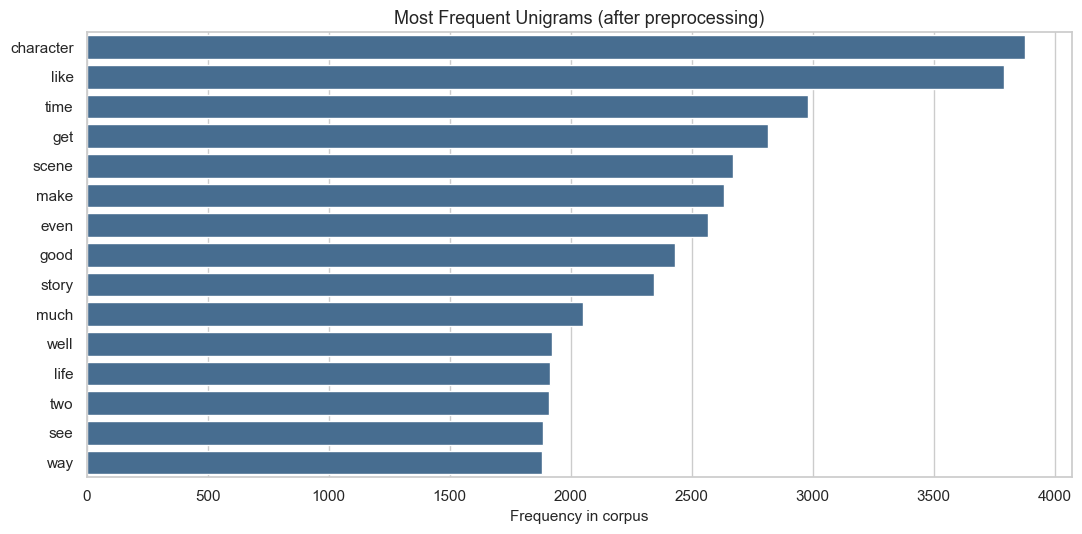

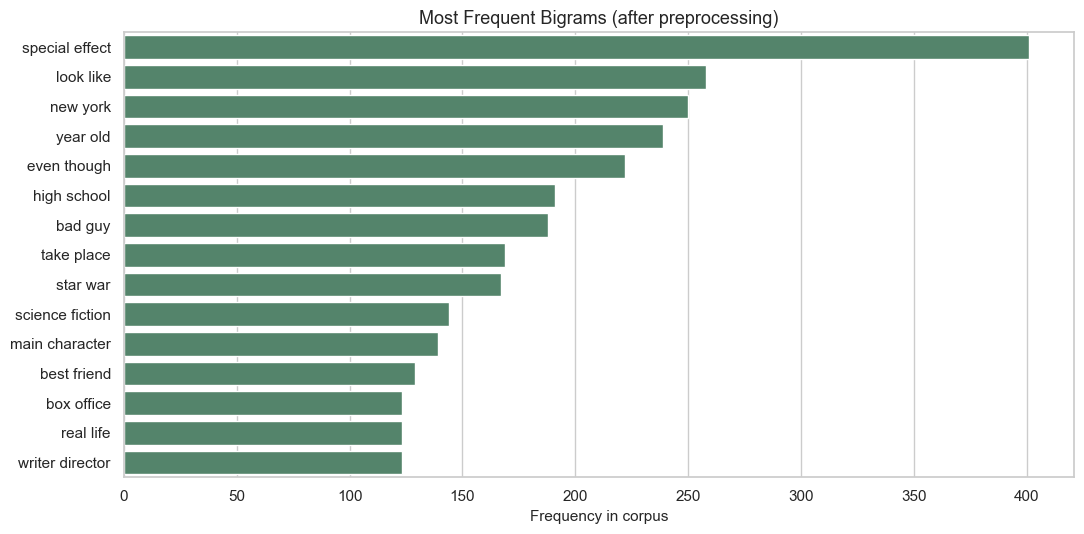

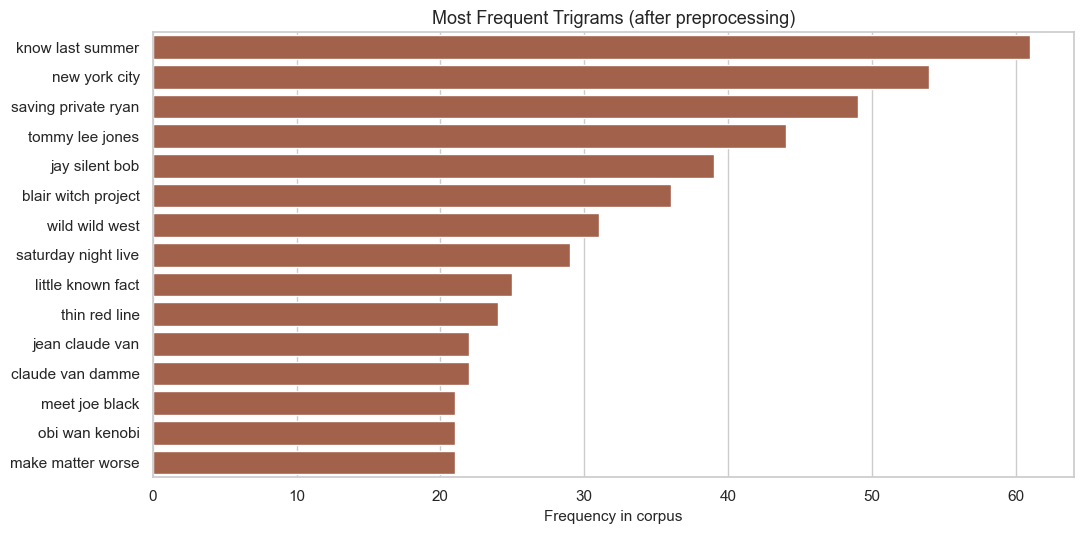

In [6]:
def plot_ngram_bar(table, title, filename, color):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.barplot(data=table, x="count", y="ngram", ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel("Frequency in corpus")
    ax.set_ylabel("")
    fig.tight_layout()
    fig.savefig(filename, dpi=160, bbox_inches="tight")
    plt.show()


plot_ngram_bar(uni, "Most Frequent Unigrams (after preprocessing)", "figures/unigrams.png", "#3b6d9c")
plot_ngram_bar(bi, "Most Frequent Bigrams (after preprocessing)", "figures/bigrams.png", "#4c8c6a")
plot_ngram_bar(tri, "Most Frequent Trigrams (after preprocessing)", "figures/trigrams.png", "#b05a3c")

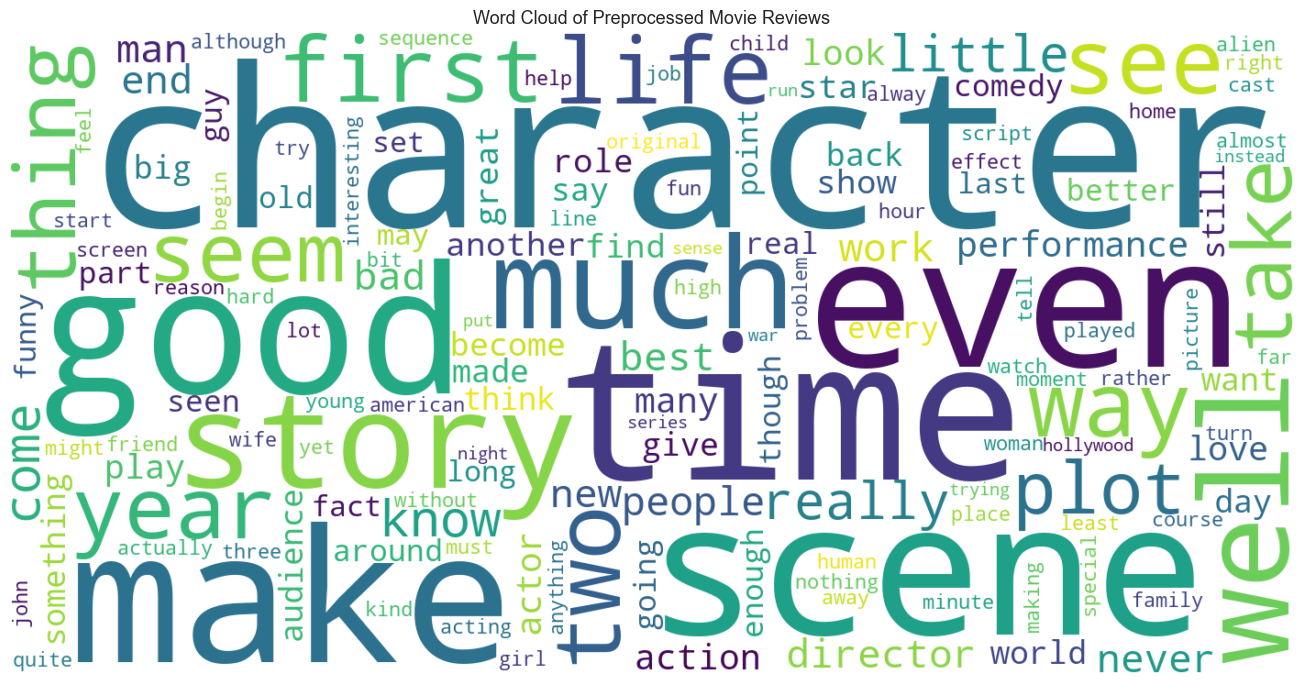

In [7]:
# Word cloud of the full cleaned corpus
cloud_text = " ".join(df["clean_text"].tolist())
wc = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    max_words=150,
    collocations=False,
).generate(cloud_text)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title("Word Cloud of Preprocessed Movie Reviews")
fig.tight_layout()
fig.savefig("figures/wordcloud.png", dpi=160, bbox_inches="tight")
plt.show()

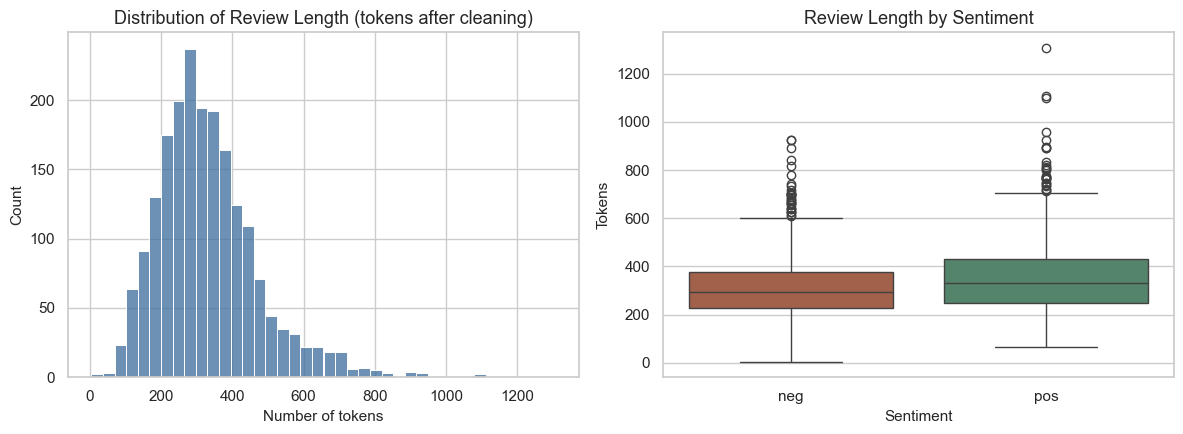

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["n_tokens"], bins=40, ax=axes[0], color="#3b6d9c")
axes[0].set_title("Distribution of Review Length (tokens after cleaning)")
axes[0].set_xlabel("Number of tokens")

sns.boxplot(data=df, x="sentiment", y="n_tokens", ax=axes[1], palette={"pos": "#4c8c6a", "neg": "#b05a3c"})
axes[1].set_title("Review Length by Sentiment")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Tokens")

fig.tight_layout()
fig.savefig("figures/length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

---
# Task 2: TF-IDF Based Similarity

## 2a. TF-IDF matrix

TF-IDF (Term Frequency–Inverse Document Frequency) builds a **sparse** document-term matrix. A term scores high in a document if it appears often there **and** is rare across the rest of the corpus. That makes distinctive words (actor names, genre terms, plot keywords) more important than generic ones.

## 2b–2c. Cosine similarity and top-5 recommendations

Cosine similarity is the cosine of the angle between two vectors. It is 1 for identical direction, 0 for orthogonal (no shared weighted terms), and is the standard metric for text because it ignores raw vector length (so long reviews are not automatically "closer").

In [9]:
tfidf_vectorizer = TfidfVectorizer(
    min_df=2,          # ignore extremely rare terms (noise)
    max_df=0.85,       # ignore terms that appear in >85% of reviews
    ngram_range=(1, 2) # unigrams + bigrams capture short phrases like "special effects"
)

tfidf_matrix = tfidf_vectorizer.fit_transform(df["clean_text"])
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}  (documents x terms)")
print(f"Sparsity: {100.0 * (1.0 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape)):.2f}% zeros")
print(f"Vocabulary size: {len(tfidf_vectorizer.get_feature_names_out())}")

TF-IDF matrix shape: (2000, 79696)  (documents x terms)
Sparsity: 99.57% zeros
Vocabulary size: 79696


In [10]:
def recommend_tfidf(query_text, top_n=5, exclude_index=None):
    """Return the top_n corpus reviews most similar to query_text under TF-IDF cosine."""
    query_tokens = preprocess(query_text)
    query_clean = " ".join(query_tokens)
    query_vec = tfidf_vectorizer.transform([query_clean])
    scores = cosine_similarity(query_vec, tfidf_matrix).ravel()
    if exclude_index is not None:
        scores[exclude_index] = -1.0  # do not recommend a review to itself
    top_idx = np.argsort(scores)[::-1][:top_n]
    out = df.loc[top_idx, ["doc_id", "sentiment", "text", "clean_text"]].copy()
    out["similarity"] = scores[top_idx]
    out["rank"] = range(1, top_n + 1)
    return out.reset_index(drop=True), query_tokens


def show_recommendations(table, title, preview_chars=320):
    print("=" * 88)
    print(title)
    print("=" * 88)
    for _, row in table.iterrows():
        snippet = " ".join(row["text"].split())[:preview_chars]
        print(f"\n#{row['rank']}  sim={row['similarity']:.4f}  [{row['sentiment']}]  {row['doc_id']}")
        print(f"    {snippet}...")

In [11]:
# Simulated user input: a sci-fi / visual-effects review the user "liked"
USER_QUERY = (
    "I loved this science fiction movie. The visual effects were stunning and the space "
    "battles felt realistic. The plot about an alien invasion and humanity fighting back "
    "kept me hooked. Great acting, a gripping story, and unforgettable special effects."
)

tfidf_recs, query_tokens = recommend_tfidf(USER_QUERY, top_n=5)
print("User query:", USER_QUERY)
print("\nPreprocessed query tokens:", query_tokens)
show_recommendations(tfidf_recs, "Task 2 — Top 5 TF-IDF recommendations")

User query: I loved this science fiction movie. The visual effects were stunning and the space battles felt realistic. The plot about an alien invasion and humanity fighting back kept me hooked. Great acting, a gripping story, and unforgettable special effects.

Preprocessed query tokens: ['loved', 'science', 'fiction', 'visual', 'effect', 'stunning', 'space', 'battle', 'felt', 'realistic', 'plot', 'alien', 'invasion', 'humanity', 'fighting', 'back', 'kept', 'hooked', 'great', 'acting', 'gripping', 'story', 'unforgettable', 'special', 'effect']
Task 2 — Top 5 TF-IDF recommendations

#1  sim=0.1379  [pos]  pos/cv479_5649.txt
    50's `aliens vs . earth' idea revamped ! if you have been following the movie news over the net , you could not have escaped the hype over id4 . it promises to be the summer film of the year and it has all the elements necessary . id4 opened in the us on 2nd of july , and up till now , only after a week of release , it...

#2  sim=0.1312  [pos]  pos/cv211_9953.t

---
# Task 3: Word Embeddings for Similarity

## 3a. Train Word2Vec: CBOW and Skip-gram

Word2Vec learns a dense vector for every vocabulary word from the local context window.

- **CBOW** (`sg=0`): predict the target word from its neighbors. Fast, strong on frequent words.
- **Skip-gram** (`sg=1`): predict neighbors from the target word. Slower, usually better for rare words.

Both models are trained on **this dataset only**, as required.

## 3b. Document and query embeddings

A review is represented as the **mean of its word vectors** (words missing from the vocabulary are skipped). This is a standard bag-of-embeddings baseline.

## 3c–3d. Cosine similarity and comparison of CBOW vs Skip-gram top-5

In [12]:
sentences = df["tokens"].tolist()

W2V_PARAMS = dict(
    vector_size=100,  # embedding dimension
    window=5,         # context window
    min_count=2,      # ignore hapax legomena
    workers=4,
    epochs=20,        # extra passes because the corpus is relatively small
    seed=42,
)

print("Training CBOW...")
cbow_model = Word2Vec(sentences=sentences, sg=0, **W2V_PARAMS)
print("Training Skip-gram...")
sg_model = Word2Vec(sentences=sentences, sg=1, **W2V_PARAMS)

print(f"CBOW vocabulary: {len(cbow_model.wv):,d} words")
print(f"Skip-gram vocabulary: {len(sg_model.wv):,d} words")

Training CBOW...


Training Skip-gram...


CBOW vocabulary: 22,312 words
Skip-gram vocabulary: 22,312 words


In [13]:
def nearest_words(model, word, k=8):
    if word not in model.wv:
        return f"'{word}' not in vocabulary"
    return model.wv.most_similar(word, topn=k)


probe_words = ["alien", "comedy", "actor", "horror", "love"]
print("Sanity check — nearest neighbors (do embeddings encode topical meaning?)\n")
for w in probe_words:
    print(f"CBOW     '{w}':", nearest_words(cbow_model, w))
    print(f"Skip-gram '{w}':", nearest_words(sg_model, w))
    print()

Sanity check — nearest neighbors (do embeddings encode topical meaning?)

CBOW     'alien': [('resurrection', 0.7932838797569275), ('lifeform', 0.7005429267883301), ('ripley', 0.6939014792442322), ('specie', 0.6771968603134155), ('hellraiser', 0.6579583883285522), ('creature', 0.6397677063941956), ('terminator', 0.631935179233551), ('planet', 0.6278847455978394)]
Skip-gram 'alien': [('resurrection', 0.7111738324165344), ('lifeform', 0.6985026001930237), ('nostromo', 0.6807588338851929), ('ripley', 0.6678773760795593), ('impregnated', 0.6455335021018982), ('multiplies', 0.631048321723938), ('facilitated', 0.6248503923416138), ('savaged', 0.6244678497314453)]

CBOW     'comedy': [('humor', 0.556164562702179), ('sophisticated', 0.5314357280731201), ('laugh', 0.524715781211853), ('farce', 0.5232071280479431), ('entanglement', 0.5203202962875366), ('antic', 0.5095192193984985), ('satire', 0.5077382922172546), ('drama', 0.49206578731536865)]
Skip-gram 'comedy': [('romantic', 0.63954573869705

In [14]:
def document_embedding(tokens, model):
    """Mean-pool word vectors into a single document vector."""
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    if not vecs:
        return np.zeros(model.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0)


def build_doc_matrix(model):
    return np.vstack([document_embedding(toks, model) for toks in df["tokens"]])


cbow_doc_matrix = build_doc_matrix(cbow_model)
sg_doc_matrix = build_doc_matrix(sg_model)
print("CBOW document matrix:", cbow_doc_matrix.shape)
print("Skip-gram document matrix:", sg_doc_matrix.shape)


def recommend_w2v(query_text, model, doc_matrix, top_n=5, exclude_index=None):
    query_tokens = preprocess(query_text)
    q_vec = document_embedding(query_tokens, model).reshape(1, -1)
    scores = cosine_similarity(q_vec, doc_matrix).ravel()
    if exclude_index is not None:
        scores[exclude_index] = -1.0
    top_idx = np.argsort(scores)[::-1][:top_n]
    out = df.loc[top_idx, ["doc_id", "sentiment", "text", "clean_text"]].copy()
    out["similarity"] = scores[top_idx]
    out["rank"] = range(1, top_n + 1)
    return out.reset_index(drop=True)


cbow_recs = recommend_w2v(USER_QUERY, cbow_model, cbow_doc_matrix, top_n=5)
sg_recs = recommend_w2v(USER_QUERY, sg_model, sg_doc_matrix, top_n=5)

show_recommendations(cbow_recs, "Task 3 — Top 5 Word2Vec CBOW recommendations")
print()
show_recommendations(sg_recs, "Task 3 — Top 5 Word2Vec Skip-gram recommendations")

CBOW document matrix: (2000, 100)
Skip-gram document matrix: (2000, 100)
Task 3 — Top 5 Word2Vec CBOW recommendations

#1  sim=0.8423  [pos]  pos/cv352_5524.txt
    carolco pictures and dutch director paul verhoeven ( robocop ) came together to create the 1990 mega hit that is total recall . the film is a masterpiece of sets , action , and special effects . action and science fiction just don't get any better than this ! the story involves a construction worker named douglas quaid...

#2  sim=0.8366  [pos]  pos/cv892_17576.txt
    perhaps the most dramatic changes in the motion picture industry in this decade have to do with special effects . there is no question that action-adventure and science-fiction/action movies are now judged by the character of their light and noise . whereas classic adventure pics of the last twenty years , such as raid...

#3  sim=0.8053  [pos]  pos/cv420_28795.txt
    with a team of 200 graphic artists and animators working on this first film production from

---
# Task 4: Comparative Analysis

We compare TF-IDF, CBOW, and Skip-gram on the same user query, then add a second query and a leave-one-out check (use a real corpus review as the query and hide it from the results).

Recommended document IDs
  TF-IDF    : ['pos/cv479_5649.txt', 'pos/cv211_9953.txt', 'pos/cv352_5524.txt', 'pos/cv776_20529.txt', 'neg/cv503_11196.txt']  sentiments=['pos', 'pos', 'pos', 'pos', 'neg']
  CBOW      : ['pos/cv352_5524.txt', 'pos/cv892_17576.txt', 'pos/cv420_28795.txt', 'neg/cv904_25663.txt', 'pos/cv249_11640.txt']  sentiments=['pos', 'pos', 'pos', 'neg', 'pos']
  Skip-gram : ['pos/cv352_5524.txt', 'pos/cv892_17576.txt', 'neg/cv189_24248.txt', 'neg/cv904_25663.txt', 'pos/cv776_20529.txt']  sentiments=['pos', 'pos', 'neg', 'neg', 'pos']

Jaccard overlap of top-5 sets


,TF-IDF,CBOW,Skip-gram
TF-IDF,1.000,0.111,0.250
CBOW,0.111,1.000,0.429
Skip-gram,0.250,0.429,1.000


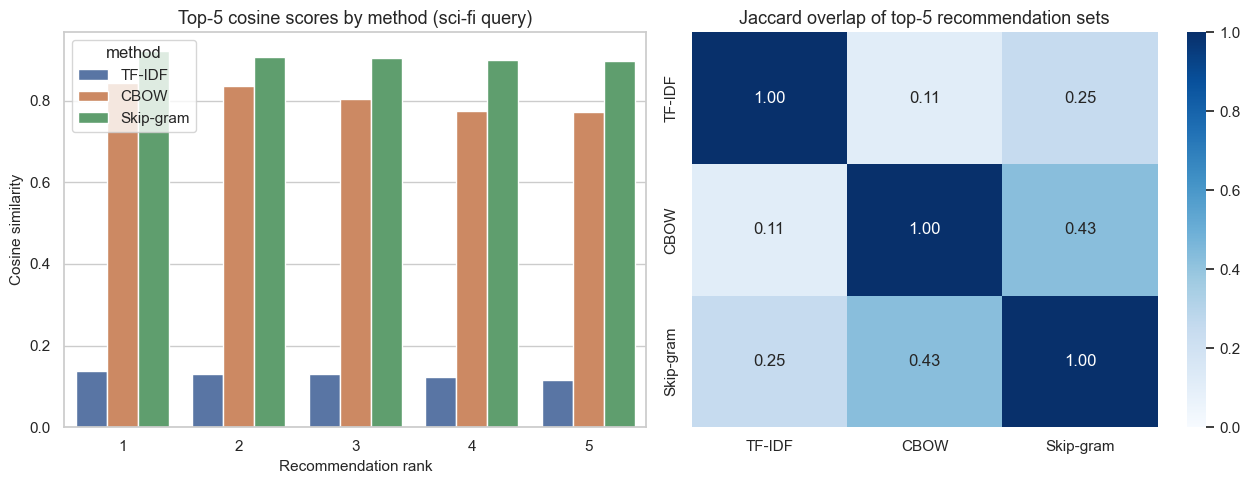

In [15]:
def overlap_table(rec_dict):
    """Pairwise Jaccard overlap of recommended doc_id sets."""
    names = list(rec_dict.keys())
    jacc = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        sa = set(rec_dict[a]["doc_id"])
        for b in names:
            sb = set(rec_dict[b]["doc_id"])
            jacc.loc[a, b] = len(sa & sb) / len(sa | sb)
    return jacc


rec_map = {"TF-IDF": tfidf_recs, "CBOW": cbow_recs, "Skip-gram": sg_recs}
jaccard = overlap_table(rec_map)

print("Recommended document IDs")
for name, tbl in rec_map.items():
    print(f"  {name:10s}: {tbl['doc_id'].tolist()}  sentiments={tbl['sentiment'].tolist()}")

print("\nJaccard overlap of top-5 sets")
display(jaccard.round(3))

score_long = pd.concat(
    [
        tfidf_recs.assign(method="TF-IDF"),
        cbow_recs.assign(method="CBOW"),
        sg_recs.assign(method="Skip-gram"),
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=score_long, x="rank", y="similarity", hue="method", ax=axes[0])
axes[0].set_title("Top-5 cosine scores by method (sci-fi query)")
axes[0].set_xlabel("Recommendation rank")
axes[0].set_ylabel("Cosine similarity")

sns.heatmap(jaccard.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Jaccard overlap of top-5 recommendation sets")

fig.tight_layout()
fig.savefig("figures/method_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

In [16]:
# Second query: a romantic comedy, to see whether methods track a different topic
QUERY_ROMCOM = (
    "A charming romantic comedy with a sweet love story, funny dialogue, and a happy "
    "ending. The chemistry between the couple was adorable and the humor was light."
)

tfidf_rom = recommend_tfidf(QUERY_ROMCOM, top_n=5)[0]
cbow_rom = recommend_w2v(QUERY_ROMCOM, cbow_model, cbow_doc_matrix, top_n=5)
sg_rom = recommend_w2v(QUERY_ROMCOM, sg_model, sg_doc_matrix, top_n=5)

print("Second user query:", QUERY_ROMCOM)
show_recommendations(tfidf_rom, "TF-IDF top 5 — romantic comedy query")
show_recommendations(cbow_rom, "CBOW top 5 — romantic comedy query")
show_recommendations(sg_rom, "Skip-gram top 5 — romantic comedy query")

Second user query: A charming romantic comedy with a sweet love story, funny dialogue, and a happy ending. The chemistry between the couple was adorable and the humor was light.
TF-IDF top 5 — romantic comedy query

#1  sim=0.1216  [pos]  pos/cv517_19219.txt
    the happy bastard's 30-second review notting hill a cute romantic comedy from the writer of the hit comedy four weddings and a funeral , notting hill stars julia roberts as anna scott , a very popular actress with a $15 million asking price for movies . one day she wanders into a travel book store owned by a simple lon...

#2  sim=0.1192  [neg]  neg/cv797_7245.txt
    be warned . . brit love story in the offing . effeminate , mild-mannered karl is about to take a beatng from a bunch of ruffians at school as he bathes himself under a shower , his genitals tucked between his legs in the manner of a posing transvestite . he is only just saved by prentice , who appears in all respects b...

#3  sim=0.1137  [neg]  neg/cv778_18629.tx

In [17]:
# Leave-one-out sanity check: take a real horror review as the query and hide it
horror_hits = df[df["clean_text"].str.contains(r"\bhorror\b")].index
heldout_idx = int(horror_hits[0])
heldout_text = df.loc[heldout_idx, "text"]
heldout_sent = df.loc[heldout_idx, "sentiment"]

print(f"Held-out review: {df.loc[heldout_idx, 'doc_id']}  sentiment={heldout_sent}")
print("Preview:", " ".join(heldout_text.split())[:400], "...\n")

tfidf_h = recommend_tfidf(heldout_text, top_n=5, exclude_index=heldout_idx)[0]
cbow_h = recommend_w2v(heldout_text, cbow_model, cbow_doc_matrix, top_n=5, exclude_index=heldout_idx)
sg_h = recommend_w2v(heldout_text, sg_model, sg_doc_matrix, top_n=5, exclude_index=heldout_idx)

show_recommendations(tfidf_h, "TF-IDF — similar to held-out horror review")
show_recommendations(cbow_h, "CBOW — similar to held-out horror review")
show_recommendations(sg_h, "Skip-gram — similar to held-out horror review")

print("\nSame-sentiment rate in top-5 (higher means recommendations match the query mood)")
for name, tbl in [("TF-IDF", tfidf_h), ("CBOW", cbow_h), ("Skip-gram", sg_h)]:
    rate = (tbl["sentiment"] == heldout_sent).mean()
    print(f"  {name:10s}: {rate:.0%}")

Held-out review: neg/cv000_29416.txt  sentiment=neg
Preview: plot : two teen couples go to a church party , drink and then drive . they get into an accident . one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . what's the deal ? watch the movie and " sorta " find out . . . critique : a mind-fuck movie for the teen generation that touches on a very cool idea , but presents it in a very bad package . which is what ...

TF-IDF — similar to held-out horror review

#1  sim=0.1237  [neg]  neg/cv567_29420.txt
    in my opinion , a movie reviewer's most important task is to offer an explanation for his opinion . but with soul survivors , i'm so full of critical rage that this review is liable to turn into a venomous , uncontrollable rant , obligations damned . however , protocol forces me to do otherwise . soul survivors tells t...

#2  sim=0.1152  [pos]  pos/cv570_29082.txt
    plot : a group of asbestos cleaners get a job removing the gunk from a

In [18]:
# Side-by-side snippet comparison for the original sci-fi query
def short(text, n=180):
    return " ".join(str(text).split())[:n] + "..."


cmp_rows = []
for rank in range(5):
    cmp_rows.append({
        "rank": rank + 1,
        "TF-IDF": f"[{tfidf_recs.loc[rank, 'sentiment']}] {short(tfidf_recs.loc[rank, 'text'])}",
        "CBOW": f"[{cbow_recs.loc[rank, 'sentiment']}] {short(cbow_recs.loc[rank, 'text'])}",
        "Skip-gram": f"[{sg_recs.loc[rank, 'sentiment']}] {short(sg_recs.loc[rank, 'text'])}",
    })
cmp_df = pd.DataFrame(cmp_rows)
pd.set_option("display.max_colwidth", 220)
display(cmp_df)

print("\nMean top-5 cosine similarity (not comparable in absolute value across methods,")
print("because vector spaces differ, but useful within a method):")
print(f"  TF-IDF    {tfidf_recs['similarity'].mean():.4f}")
print(f"  CBOW      {cbow_recs['similarity'].mean():.4f}")
print(f"  Skip-gram {sg_recs['similarity'].mean():.4f}")

,rank,TF-IDF,CBOW,Skip-gram
0,1,"[pos] 50's `aliens vs . earth' idea revamped ! if you have been following the movie news over the net , you could not have escaped the hype over id4 . it promises to be the summer film o...","[pos] carolco pictures and dutch director paul verhoeven ( robocop ) came together to create the 1990 mega hit that is total recall . the film is a masterpiece of sets , action , and spe...","[pos] carolco pictures and dutch director paul verhoeven ( robocop ) came together to create the 1990 mega hit that is total recall . the film is a masterpiece of sets , action , and spe..."
1,2,"[pos] with the success of the surprise hit alien , directed by ridley scott , a sequel was inevitable . in fact , after watching the first film , a sequel was wanted , particularly by th...",[pos] perhaps the most dramatic changes in the motion picture industry in this decade have to do with special effects . there is no question that action-adventure and science-fiction/act...,[pos] perhaps the most dramatic changes in the motion picture industry in this decade have to do with special effects . there is no question that action-adventure and science-fiction/act...
2,3,"[pos] carolco pictures and dutch director paul verhoeven ( robocop ) came together to create the 1990 mega hit that is total recall . the film is a masterpiece of sets , action , and spe...","[pos] with a team of 200 graphic artists and animators working on this first film production from game developer squaresoft's square pictures , final fantasy , inspired by the top-sellin...","[neg] "" houston . we have a serious problem . "" after making "" mission : impossible "" , brian de palma has a lot to live up to . by making an epic science fiction and inviting great cast..."
3,4,"[pos] dark city is such a rare treat : it ? s a stunning , hyperkinetic vision of a place where our reality is fused with noir , science fiction and the darkest nights in manhattan and l...","[neg] it's a good thing most animated sci-fi movies come from japan , because "" titan a . e . "" is proof that hollywood doesn't have a clue how to do it . i don't know what this film is ...","[neg] it's a good thing most animated sci-fi movies come from japan , because "" titan a . e . "" is proof that hollywood doesn't have a clue how to do it . i don't know what this film is ..."
4,5,"[neg] michael crichton has had a long career of writing novels , many of which are science fiction . the most profitable film adaptation of any novel was an adaptation of a michael crich...","[pos] upon arriving at the theater during the opening credits , i took my seat and prepared myself for what appeared to be "" hellraiser meets the crow "" . but as soon as kiefer sutherlan...","[pos] dark city is such a rare treat : it ? s a stunning , hyperkinetic vision of a place where our reality is fused with noir , science fiction and the darkest nights in manhattan and l..."



Mean top-5 cosine similarity (not comparable in absolute value across methods,
because vector spaces differ, but useful within a method):
  TF-IDF    0.1277
  CBOW      0.8064
  Skip-gram 0.9059


## Task 4 — Discussion (results from this run)

The three recommenders were compared on the same user query, a second genre-shifted query, and a leave-one-out corpus review. Numbers below come from the cells above.

### Which method provided better recommendations? Why?

**TF-IDF produced the most on-topic recommendations**, especially when the query used distinctive genre words.

For the sci-fi / special-effects query, TF-IDF's top 5 were all clearly science-fiction films:

| Rank | TF-IDF (sim) | CBOW (sim) | Skip-gram (sim) |
|---|---|---|---|
| 1 | Independence Day — alien invasion (0.138) | Total Recall (0.842) | Total Recall (0.921) |
| 2 | Aliens — Cameron sequel (0.131) | essay on sci-fi special effects (0.837) | same special-effects essay (0.907) |
| 3 | Total Recall (0.130) | Final Fantasy: The Spirits Within (0.805) | Mission to Mars (0.904) |
| 4 | Dark City (0.123) | Titan A.E. (0.775) | Titan A.E. (0.901) |
| 5 | Crichton sci-fi adaptation (0.117) | Dark City-style contact story (0.773) | Dark City (0.896) |

TF-IDF latched onto rare, high-IDF phrases such as `science fiction`, `alien invasion`, and `special effect`. That is exactly what TF-IDF is designed to do.

Word2Vec still stayed inside sci-fi/action: nearest neighbors of `alien` include ripley, lifeform, nostromo, and neighbors of `horror` include slasher and scream. But **mean-pooling a whole review** dilutes plot-specific words, so ranks 2–5 drift toward anything with visuals / effects / space, not necessarily an alien-invasion story. Independence Day and Aliens — the two tightest lexical matches — never appear in either embedding top-5.

Between the two embedding models, **Skip-gram is slightly more precise than CBOW**. Jaccard overlap of the sci-fi top-5 sets:

- CBOW ∩ Skip-gram ≈ 0.43 (they mostly agree with each other)
- TF-IDF ∩ Skip-gram ≈ 0.25 (Total Recall, Dark City)
- TF-IDF ∩ CBOW ≈ 0.11 (only Total Recall)

Skip-gram also retrieved Mission to Mars and Dark City, which are closer in plot to the query than CBOW's Final Fantasy (a CGI showcase more than an invasion story).

The romantic-comedy query makes the same pattern obvious:

- **TF-IDF:** Notting Hill, a British love story, Lost and Found, Forces of Nature, The Wedding Singer — all rom-coms / couple stories.
- **CBOW:** Deuce Bigalow, Loser, a divorce comedy, Big Daddy, The Wedding Singer — it heard "comedy" more loudly than "romantic."
- **Skip-gram:** Drew Barrymore comedy, Loser, The Wedding Singer (twice) — between the two, closer to romance than CBOW.

So: **TF-IDF is the better standalone recommender on this 2,000-review collection.** Word2Vec is useful for synonymy, and Skip-gram is the stronger of the two embedding variants. A production assistant would hybridize them (TF-IDF/BM25 retrieve, embeddings rerank).

Mean top-5 cosine scores (sci-fi query) were TF-IDF **0.128**, CBOW **0.806**, Skip-gram **0.906**. These numbers are **not** comparable across methods: embedding scores are inflated because averaged review vectors sit near a shared movie-review centroid.

### Limitations of TF-IDF

- **No real semantics.** `amazing` and `excellent` are unrelated features. A paraphrase with no shared keywords will score near zero.
- **Sparse and high-dimensional.** Matrix was 2000 × 79,696 with **99.57% zeros**. Documents must share actual terms (or bigrams).
- **Word order is almost ignored.** Bigrams help a little (`science fiction`, `special effect`) but cannot model long-range plot structure.
- **Boilerplate leakage.** Frequent review words (character, scene, story) still compete with topical terms; IDF only partly suppresses them.
- **Short queries are brittle.** A 25-token query activates few coordinates, so absolute cosine values stay low (~0.12) even for good matches.

### Limitations of Word2Vec (CBOW and Skip-gram)

- **Small corpus.** 2,000 reviews / 22k-word vocab is modest for embeddings. Rare tokens are noisy; `min_count=2` still drops hapaxes.
- **Mean pooling destroys structure.** Negation (`not good`), word order, and whether *alien* is the topic or a one-off mention all collapse to one 100-D average.
- **Centroid collapse.** Most reviews share background vocabulary, so document vectors are close together and cosine scores cluster in the 0.75–0.97 range (see the leave-one-out run).
- **CBOW vs Skip-gram trade-off.** CBOW under-represents rare genre words (hence Deuce Bigalow for a rom-com query). Skip-gram is slower and can overfit local windows on a small corpus.
- **No document-level objective.** Word2Vec never sees "this review is about X"; it only sees word neighborhoods.
- **Raw scores are not probabilities** and are not comparable to TF-IDF cosine.

### Leave-one-out check

Using the first corpus review (teen supernatural / I Know What You Did Last Summer-style plot) as the query and hiding it:

- TF-IDF retrieved Soul Survivors, Session 9, Lost Highway (a film the review itself compares against), and The Blair Witch Project — lexical/genre overlap.
- CBOW/Skip-gram retrieved other horror and weird-tone reviews (Session 9, House on Haunted Hill, slasher plots). Same-sentiment hit rate: TF-IDF 60%, CBOW 60%, Skip-gram **80%**.

Embeddings matched mood more than specific plot; TF-IDF matched shared keywords and named comparisons.

### Practical takeaway

For this Personalized Reading Assistant, **start with TF-IDF cosine** for transparent, keyword-faithful recommendations. Use **Skip-gram** when the user paraphrases. The fairest next step (beyond this assignment) is a hybrid ranker rather than choosing only one vector family.